# Fallacies With Conditional Probabilities

## Linda and Steve: a Story of Farmers, Librarians, Feminists and Conditional Probabilities


{{< video https://www.youtube.com/watch?v=HZGCoVF3YvM >}}

## The Prosecutor's Fallacy

:::{.ex-class}
![Sally Clark, 1964-2007](./figures/SallyClark.jpg){style="max-width: 400px"}

In the late 1990s, Sally Clark, a British solicitor and mother of two, was accused of murdering her two children.
Her first son died of sudden infant death syndrome (SIDS) at 11 weeks, and her second son died of SIDS at 8 weeks about
two years later [@FEENY2026100714].

The prosecution argued that the probability of one child dying of SIDS is about 1 in 8,500, so the probability of two children dying of SIDS is about 1 in 73 million, so the chance that she was innocent is 1 in 73 million.

Create a counterargument to the prosecution's reasoning.

:::

::: {#sol-sally-clark .callout-note collapse="true"}
## Solution (click to expand)

**Events and assumptions.** Define

- $E$: both infants died suddenly (the evidence),
- $M^c$: both deaths are natural (SIDS), i.e. the mother is innocent,
- $M$: both infants were murdered, i.e. the mother is guilty.

For illustration, assume that for a single infant in such a family the probability of a SIDS death is $1/8543$ and the probability of a murder is $1/20{,}000$, and that the two infants are independent. The murder rate is an illustrative value, not a documented figure.

**1. Prosecution's number.** The figure $1/73$ million is the probability of the evidence if the mother is innocent:

$$
P(E \mid M^c) = \left(\frac{1}{8543}\right)^2 \approx \frac{1}{73{,}000{,}000}
$$

The court needs $P(M^c \mid E)$, the probability of innocence given that two infants have died. Reading $P(E \mid M^c)$ as $P(M^c \mid E)$ is the prosecutor's fallacy.

**2. Enumeration.** Imagine $10^9$ families with two infants. Only families in which both infants died are consistent with $E$, and there are two ways in which this can happen:

| Situation | Probability | Number of families |
|:----------|:-----------:|:------------------:|
| Both infants die of SIDS ($M^c$) | $\left(\frac{1}{8543}\right)^2 \approx \frac{1}{73{,}000{,}000}$ | $\approx 13.7$ |
| Both infants are murdered ($M$) | $\left(\frac{1}{20{,}000}\right)^2 = \frac{1}{400{,}000{,}000}$ | $2.5$ |

The rare event "two SIDS deaths" is not a reason to doubt $M^c$, because the alternative $M$ is rare as well.

**3. Bayes.** Conditioning on $E$ means keeping only the families in these two rows ($13.7 + 2.5 = 16.2$ families). Since $P(E \mid M^c) = P(E \mid M) = 1$,

$$
P(M^c \mid E) = \frac{P(E \mid M^c)\, P(M^c)}{P(E \mid M^c)\, P(M^c) + P(E \mid M)\, P(M)} = \frac{13.7}{13.7 + 2.5} \approx 0.85, \qquad P(M \mid E) \approx 0.15
$$

The probability of innocence is about $85\%$ and not $1/73$ million. Equivalently, the posterior odds are $13.7 : 2.5 \approx 5.5 : 1$ in favor of innocence.

**4. The flaws in the prosecution's argument.**

- *Mix-up of conditional probabilities.* $P(E \mid M^c)$ is small, but without $P(E \mid M)$ the number says nothing. The two explanations have to be compared, as in step 3.
- *Independence.* Squaring $1/8543$ assumes that the SIDS deaths of two siblings are independent. Siblings share genetic and environmental risk factors, so the probability of a second death after a first is higher than $1/8543$. This makes $P(M^c)$ larger and strengthens the case for innocence.

:::

We can check the counts with a short calculation.

In [1]:
prob_sids = 1 / 8543
prob_murder = 1 / 20_000  # illustrative value
families = 1_000_000_000

families_double_sids = families * prob_sids**2
families_double_murder = families * prob_murder**2
families_with_evidence = families_double_sids + families_double_murder

print(f"P(E | innocent) = {prob_sids**2:.2e}  (1/73 million = {1 / 73_000_000:.2e})")
print(f"Families with two SIDS deaths:   {families_double_sids:.1f}")
print(f"Families with two murders:       {families_double_murder:.1f}")
print(f"P(innocent | two deaths) = {families_double_sids / families_with_evidence:.3f}")
print(f"P(guilty | two deaths)   = {families_double_murder / families_with_evidence:.3f}")

P(E | innocent) = 1.37e-08  (1/73 million = 1.37e-08)
Families with two SIDS deaths:   13.7
Families with two murders:       2.5
P(innocent | two deaths) = 0.846
P(guilty | two deaths)   = 0.154


## The Defender's Fallacy

![O. J. Simpson](./figures/OJSimpson.jpeg){style="max-width: 400px"}

::: {#exr-defender-fallacy .ex-class}
## Abuse and Murder

In the 1995 murder trial of O. J. Simpson, the defense argued that a history of abuse was irrelevant to the case because "only 1 in 2500 abused women is murdered by her abuser" [@GIGERENZER2002ReckoningRiskLearning]. The same point was made by @GOOD1995WhenBattererTurns.

What is the flaw of this argument? Use Bayes' theorem to evaluate it.

Consider a woman who was abused by her partner and define the following events:

- $A$: the woman was abused by her partner.
- $M$: the woman was murdered during the period considered (one year).
- $P$: the murderer is her partner (the partner is the murderer).
- $P^c$: the murderer is someone other than her partner.

Of every 100,000 abused women, in one year:

- 40 are murdered by their partner (the event $M \cap P$),
- 5 are murdered by someone else (the event $M \cap P^c$).

:::

:::{.callout-note collapse="true"}
## Solution (click to expand)

**The defense's claim** The figure $1/2500$ is the probability that an abused woman is murdered _by her partner_ in a given year:

$$
P(M \cap P \mid A) = \frac{40}{100{,}000} = \frac{1}{2500}
$$

It averages over _all_ abused women, and almost all of them are alive. It is not the probability we need.

**Let's just count:** Out of 100,000 abused women, $40 + 5 = 45$ are murdered, and 40 of these 45 were killed by their partner.

**What does Bayes have to say:** The events $M \cap P$ and $M \cap P^c$ partition the event $M$. By the definition of conditional probability and the total probability theorem,

$$
P(P \mid A \cap M) = \frac{P(M \cap P \mid A)}{P(M \mid A)} = \frac{P(M \cap P \mid A)}{P(M \cap P \mid A) + P(M \cap P^c \mid A)} = \frac{40/100{,}000}{40/100{,}000 + 5/100{,}000} = \frac{40}{45} = \frac{8}{9} \approx 0.89
$$

This agrees with the value of about 8 in 9 reported by @GIGERENZER2002ReckoningRiskLearning.

**What is wrong with the defense's argument?** The defense conditioned on abuse ($A$) only. It left out the fact that the woman _was murdered_ ($M$). Once $M$ is known, the 99,955 abused women who were not murdered are irrelevant, and the question is how many among the murderers is the partner. The probability of the partner being the murderer is then about $8/9$ and not $1/2500$.

Both the prosecutors' and the defender's fallacies condition on the wrong event, but in opposite directions. The prosecutor's fallacy replaces $P(G^c \mid E)$ by the small number $P(E \mid G^c)$ and so _inflates_ the probability of guilt. The defender's fallacy uses a small probability that does not condition on all the known facts ($M$ is missing) and so _deflates_ it.

**Robustness.** The figure of 5 murders per 100,000 by someone else is the least well documented number. Even if it were three times as large (15 per 100,000), we would get $40/55 \approx 0.73$, which is still far from $1/2500$.
:::

We can check the counting argument with a short calculation.

In [2]:
abused_women = 100_000
murdered_by_partner = 40
murdered_by_someone_else = 5

murdered_total = murdered_by_partner + murdered_by_someone_else

print(f"P(murdered by partner | abused)         = {murdered_by_partner / abused_women:.6f}  (1/2500 = {1 / 2500:.6f})")
print(f"P(partner is murderer | abused, murdered) = {murdered_by_partner / murdered_total:.4f}  (8/9 = {8 / 9:.4f})")

P(murdered by partner | abused)         = 0.000400  (1/2500 = 0.000400)
P(partner is murderer | abused, murdered) = 0.8889  (8/9 = 0.8889)


The following diagram shows both probabilities as areas. Each rectangle represents a population, and its area is split in proportion to the counts (the sliver in the left rectangle is enlarged so that it is visible).

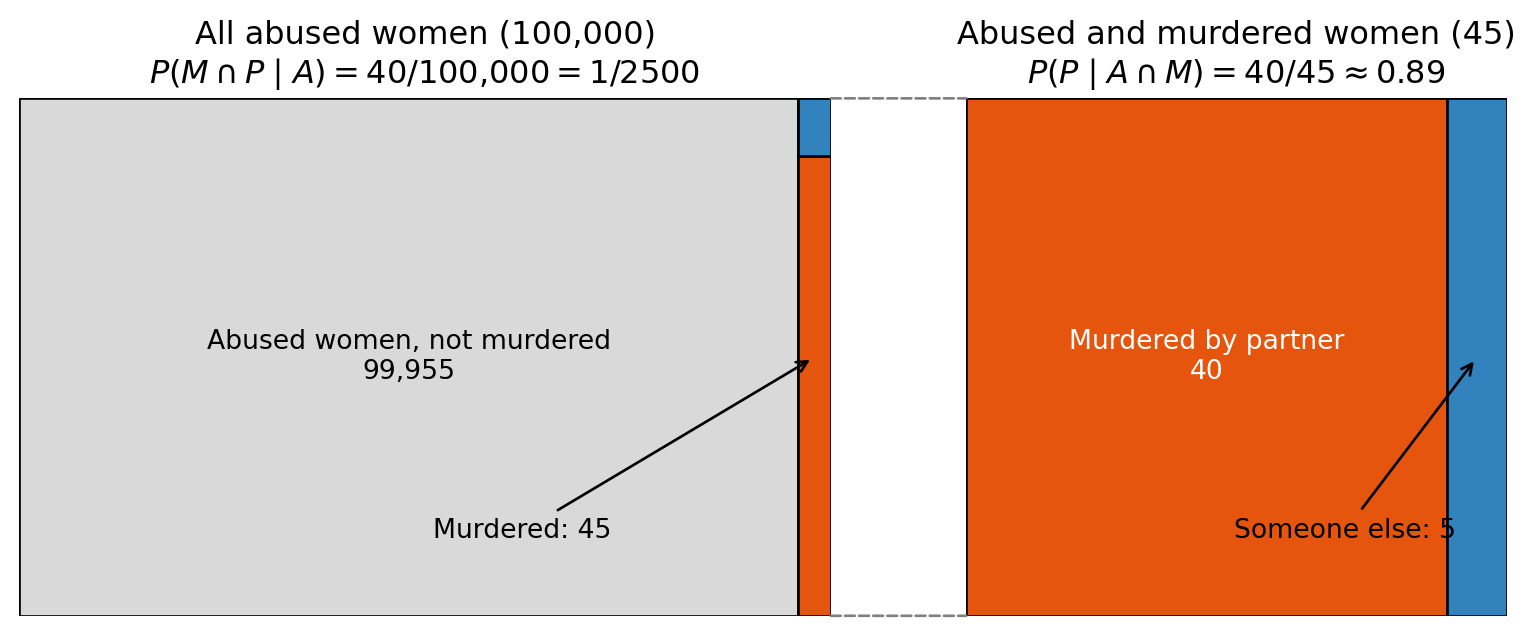

In [3]:
#| label: fig-defender-fallacy
#| fig-cap: "The defense's number is the share of the thin sliver in the left rectangle (all abused women). The relevant probability is the share of the partner among the murdered women (right rectangle)."
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, ConnectionPatch

abused_women = 100_000
murdered_by_partner = 40
murdered_by_someone_else = 5
murdered_total = murdered_by_partner + murdered_by_someone_else

fig, (ax_all, ax_murdered) = plt.subplots(
    1, 2, figsize=(10, 3.5), gridspec_kw={"width_ratios": [3, 2]}
)

# Left: all abused women (the sliver of murdered women is enlarged)
sliver_width = 0.04
ax_all.add_patch(Rectangle((0, 0), 1 - sliver_width, 1, facecolor="#d9d9d9", edgecolor="black"))
partner_height = murdered_by_partner / murdered_total
ax_all.add_patch(Rectangle((1 - sliver_width, 0), sliver_width, partner_height, facecolor="#e6550d", edgecolor="black"))
ax_all.add_patch(Rectangle((1 - sliver_width, partner_height), sliver_width, 1 - partner_height, facecolor="#3182bd", edgecolor="black"))
ax_all.annotate(f"Murdered: {murdered_total}", xy=(1 - sliver_width / 2, 0.5), xytext=(0.62, 0.15),
                arrowprops={"arrowstyle": "->"}, ha="center")
ax_all.text(0.48, 0.5, f"Abused women, not murdered\n{abused_women - murdered_total:,}", ha="center", va="center")
ax_all.set_title(f"All abused women ({abused_women:,})\n" r"$P(M \cap P \mid A) = 40/100{,}000 = 1/2500$")
ax_all.set_xlim(0, 1)
ax_all.set_ylim(0, 1)
ax_all.axis("off")

# Right: only the murdered women
partner_share = murdered_by_partner / murdered_total
ax_murdered.add_patch(Rectangle((0, 0), partner_share, 1, facecolor="#e6550d", edgecolor="black"))
ax_murdered.add_patch(Rectangle((partner_share, 0), 1 - partner_share, 1, facecolor="#3182bd", edgecolor="black"))
ax_murdered.text(partner_share / 2, 0.5, f"Murdered by partner\n{murdered_by_partner}", ha="center", va="center", color="white")
ax_murdered.annotate(f"Someone else: {murdered_by_someone_else}", xy=(partner_share + (1 - partner_share) / 2, 0.5),
                     xytext=(0.7, 0.15), arrowprops={"arrowstyle": "->"}, ha="center")
ax_murdered.set_title(f"Abused and murdered women ({murdered_total})\n" r"$P(P \mid A \cap M) = 40/45 \approx 0.89$")
ax_murdered.set_xlim(0, 1)
ax_murdered.set_ylim(0, 1)
ax_murdered.axis("off")

# Connect the sliver to the right rectangle to show the zoom
for y_value in (0, 1):
    fig.add_artist(ConnectionPatch(
        xyA=(1, y_value), coordsA=ax_all.transData,
        xyB=(0, y_value), coordsB=ax_murdered.transData,
        color="gray", linestyle="--",
    ))

plt.show()

## A Tale of Three Prisoners

::: {#exr-conditional-probability-three-prisoners .ex-class}
## Three Prisoners

Three prisoners, $A$, $B$ and $C$, are held in separate cells. The governor decides to pardon one of them and chooses at random with equal probability. A guard in the prison learns who will be released, but is not allowed to tell.

Prisoner $A$ asks the guard: "Name one of the other two who will remain in prison." The guard answers "$B$ will remain in prison."

- The guard thinks: whoever is released, B or C will remain in prison, so I have given $A$ no information about his own chances of being released.
- $A$ reasons: "Now only $A$ and $C$ remain, so my chance of being released has risen from $1/3$ to $1/2$."

Whose line of reasoning would you support?

:::

::: {#sol-three-prisoners .callout-note collapse="true"}
## Solution (click to expand)

**1. Enumeration.** Each prisoner is released with probability $1/3$. The guard's answer depends on who is released:

| Released | Guard says | Probability |
|:--------:|:----------:|:-----------:|
| $A$ | $B$ | $\frac{1}{3} \cdot \frac{1}{2} = \frac{1}{6}$ |
| $A$ | $C$ | $\frac{1}{3} \cdot \frac{1}{2} = \frac{1}{6}$ |
| $B$ | $C$ | $\frac{1}{3} \cdot 1 = \frac{1}{3}$ |
| $C$ | $B$ | $\frac{1}{3} \cdot 1 = \frac{1}{3}$ |

The four rows are mutually exclusive and exhaustive, so the probabilities add up to $1$. If $B$ is released, the guard cannot name $B$ and must say $C$; if $C$ is released, he must say $B$.

**2. Conditioning.** The event $N_B$ consists of the rows (released $A$, says $B$) and (released $C$, says $B$):

$$
P(N_B) = \frac{1}{6} + \frac{1}{3} = \frac{1}{2}
$$

Conditioning means keeping only these two rows and dividing by their total probability:

$$
P(R_A \mid N_B) = \frac{P(R_A \cap N_B)}{P(N_B)} = \frac{1/6}{1/2} = \frac{1}{3}, \qquad
P(R_C \mid N_B) = \frac{P(R_C \cap N_B)}{P(N_B)} = \frac{1/3}{1/2} = \frac{2}{3}, \qquad
P(R_B \mid N_B) = 0
$$

The probability that $A$ is released stays at $1/3$, while the probability for $C$ rises to $2/3$.

**3. The flaw.** $A$ treated the two remaining prisoners as equally likely. But the two rows that survive have different probabilities: when $A$ is released the guard has two options and says "$B$" only half of the time, whereas when $C$ is released he is *forced* to say "$B$". The answer is therefore twice as likely under $R_C$ as under $R_A$. Equivalently, $P(N_B \mid R_A) = 1/2 \neq P(N_B \mid R_C) = 1$, so the likelihoods differ and the prior $1/3 : 1/3$ becomes $1/6 : 1/3 = 1 : 2$.

**Conditioning on an event with probability 1.** Whoever is released, at least one of $B$ and $C$ remains in prison, so the guard can always name one of them. Let $S = N_B \cup N_C$ be the event "the guard names $B$ or $C$". From the table, $P(S) = 1$, and conditioning on an event with probability $1$ changes nothing:

$$
P(R_A \mid S) = \frac{P(R_A \cap S)}{P(S)} = P(R_A) = \frac{1}{3}
$$

This is what $A$ learns from the fact that the guard answered. $A$ only learns something new from *which* name the guard gives, and the name is informative only because the guard names $B$ with different probability under different hypotheses: $P(N_B \mid R_A) = 1/2$ but $P(N_B \mid R_C) = 1$. The same enumeration gives $P(R_A \mid N_C) = \frac{1/6}{1/2} = \frac{1}{3}$ as well, so $A$ knew in advance that the posterior would be $1/3$ for either answer. If both posteriors were $1/2$, the law of total probability would give

$$
P(R_A) = P(N_B)\,P(R_A \mid N_B) + P(N_C)\,P(R_A \mid N_C) = \frac{1}{2}\cdot\frac{1}{2} + \frac{1}{2}\cdot\frac{1}{2} = \frac{1}{2} \neq \frac{1}{3}
$$

which is a contradiction. With the correct values, $\frac{1}{2}\cdot\frac{1}{3} + \frac{1}{2}\cdot\frac{1}{3} = \frac{1}{3}$.

Given that the guard said "$B$ will remain in prison" and this is true, only the rows (released $A$, says $B$) and (released $C$, says $B$) remain, each with probability $1/6$:

$$
P(R_A \mid N_B, \text{ true}) = \frac{1/6}{1/6 + 1/6} = \frac{1}{2}
$$

Now $A$'s intuition is correct. The lesson is that the conditional probability depends on the *rule that generated the evidence* (the guard's protocol), not only on the evidence itself.
:::

We can check the enumeration with a short calculation. Each outcome is a (released prisoner, guard's answer) pair with its probability.

In [4]:
from fractions import Fraction

prisoners = ["A", "B", "C"]

# Enumerate all (released, guard's answer) pairs with their probabilities
outcomes = {}
for released in prisoners:
    # The guard never names A and never names the prisoner who is released
    allowed_answers = [name for name in ["B", "C"] if name != released]
    for answer in allowed_answers:
        outcomes[(released, answer)] = Fraction(1, 3) * Fraction(1, len(allowed_answers))

for (released, answer), probability in outcomes.items():
    print(f"released = {released}, guard says {answer}: {probability}")

# Condition on the guard saying "B": keep the consistent outcomes and renormalize
consistent = {outcome: p for outcome, p in outcomes.items() if outcome[1] == "B"}
probability_says_b = sum(consistent.values())
print(f"\nP(guard says B) = {probability_says_b}")

for prisoner in prisoners:
    joint = sum(p for (released, _), p in consistent.items() if released == prisoner)
    print(f"P({prisoner} released | guard says B) = {joint / probability_says_b}")

released = A, guard says B: 1/6
released = A, guard says C: 1/6
released = B, guard says C: 1/3
released = C, guard says B: 1/3

P(guard says B) = 1/2
P(A released | guard says B) = 1/3
P(B released | guard says B) = 0
P(C released | guard says B) = 2/3
